# Self Organising Maps

Using self-organising maps to visualise the feature space (NOT IMPLEMENTED)

In [1]:
import sys

In [2]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
sampling_rate = 50e6
std_noise = 0.01

sample_time = 20 / 2e6
data_len = int(sample_time * sampling_rate)

wavelet = "db20"
levels = 4
mode = "symmetric"


### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.


In [42]:
def generate_training_data_with_wavelet(wavelet, sampling_rate):
    wpt_df = None
    for R_init in (i / 1E6 for i in range(4, 11, 2)):
        for frequency in [i * 1E5 for i in range(7, 10)]:
            for pac in [-i * 1E4 for i in range(1, 20)]:
                print(R_init, frequency, pac)
                data = train.get_data(R_init, frequency, pac, sampling_rate)
                data = data / np.std(data)
                data += np.random.normal(0, std_noise, size=len(data))
                # data = data[:data_len]

                # Generate traning data using the wavelet transform
                training_data = train.generate_training_data(
                    data, levels, wavelet, mode, print_nodes_kept=False, min_entropy=True,
                )

                if wpt_df is None:  # Init dataframe
                    wpt_df = training_data
                else:  # Add data to dataframe
                    wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

    display(wpt_df)
    return wpt_df

In [43]:
wpt_df = generate_training_data_with_wavelet(wavelet, sampling_rate)

4e-06 700000.0 -10000.0
4e-06 700000.0 -20000.0
4e-06 700000.0 -30000.0
4e-06 700000.0 -40000.0
4e-06 700000.0 -50000.0
4e-06 700000.0 -60000.0
4e-06 700000.0 -70000.0
4e-06 700000.0 -80000.0
4e-06 700000.0 -90000.0
4e-06 700000.0 -100000.0
4e-06 700000.0 -110000.0
4e-06 700000.0 -120000.0
4e-06 700000.0 -130000.0
4e-06 700000.0 -140000.0
4e-06 700000.0 -150000.0
4e-06 700000.0 -160000.0
4e-06 700000.0 -170000.0
4e-06 700000.0 -180000.0
4e-06 700000.0 -190000.0
4e-06 800000.0 -10000.0
4e-06 800000.0 -20000.0
4e-06 800000.0 -30000.0
4e-06 800000.0 -40000.0
4e-06 800000.0 -50000.0
4e-06 800000.0 -60000.0
4e-06 800000.0 -70000.0
4e-06 800000.0 -80000.0
4e-06 800000.0 -90000.0
4e-06 800000.0 -100000.0
4e-06 800000.0 -110000.0
4e-06 800000.0 -120000.0
4e-06 800000.0 -130000.0
4e-06 800000.0 -140000.0
4e-06 800000.0 -150000.0
4e-06 800000.0 -160000.0
4e-06 800000.0 -170000.0
4e-06 800000.0 -180000.0
4e-06 800000.0 -190000.0
4e-06 900000.0 -10000.0
4e-06 900000.0 -20000.0
4e-06 900000.0 -3000

,level,node number,frequency range,centre frequency,energy,log energy,kurtosis,crest factor,skewness,abs skewness,entropy,spectral entropy,level entropy
0,3,0,"(0, 1.25e-1)",0.0625,2.304374e+09,9.362553,2.259011,1.002407,0.362612,0.362612,5.356585,0.000017,6.157471e+00
1,3,1,"(1.25e-1, 2.5e-1)",0.1875,6.526292e-01,-0.185334,17.579595,5.937132,-0.276644,0.276644,3.108031,7.077014,8.382294e-09
2,2,1,"(2.5e-1, 5.0e-1)",0.3750,1.470294e-01,-0.832596,25.804238,9.162562,1.718003,1.718003,3.959816,7.609378,2.065911e-09
3,1,1,"(5.0e-1, 1e0)",0.7500,1.064996e-01,-0.972652,3.296682,3.301789,-0.019688,0.019688,5.840653,8.935536,1.617364e-09
4,3,0,"(0, 1.25e-1)",0.0625,5.237342e+08,8.719111,2.719141,1.005722,0.708642,0.708642,5.356581,0.000067,6.157348e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
932,1,1,"(5.0e-1, 1e0)",0.7500,4.233216e+00,0.626670,96.437334,11.209344,-0.475615,0.475615,2.075823,8.748954,5.915694e-05
933,3,0,"(0, 1.25e-1)",0.0625,1.164430e+06,6.066113,1.875003,1.063589,-0.202272,0.202272,5.151149,0.016133,6.165512e+00
934,3,1,"(1.25e-1, 2.5e-1)",0.1875,1.560579e+00,0.193286,24.064973,4.412456,-2.413810,2.413810,2.678916,6.694168,2.679622e-05
935,2,1,"(2.5e-1, 5.0e-1)",0.3750,5.884223e-01,-0.230311,27.554443,8.251493,2.602352,2.602352,3.239462,7.738684,1.107489e-05


### Training

Train algorithm on the generated data

In [44]:
n_data_points = wpt_df.shape[0]
print("data points", n_data_points)
n_neurons = 5 * n_data_points ** (1 / 2)
print("neurons", n_neurons)

data points 937
neurons 153.05227865013967


### Feature selection

In [45]:
from sklearn.preprocessing import StandardScaler
from sklearn_som.som import SOM

# Get data, select which features to analyse
classifying_metrics = [
    "centre frequency",
    "energy",
    "log energy",
    "crest factor",
    "abs skewness",
    "kurtosis",
    "entropy",
    "spectral entropy",
    "level entropy",
]
n_metrics = len(classifying_metrics)
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Self organising maps
som_rows = int(np.sqrt(n_neurons))
som_size = (som_rows, int(n_neurons / som_rows))  # set size
som_width, som_height = som_size
n_clusters = som_width * som_height
som = SOM(som_width, som_height, n_metrics, max_iter=50000)
labels = som.fit_predict(data_train_normalised, epochs=100)
print("itertations", som.n_iter_)

# Cluster centres
centers = som.cluster_centers_
# display(centers)
centers = som.cluster_centers_.reshape((n_clusters, n_metrics))
# print(centers)
centers = scaler.inverse_transform(centers)

# print("centers:", centers)

itertations 50001


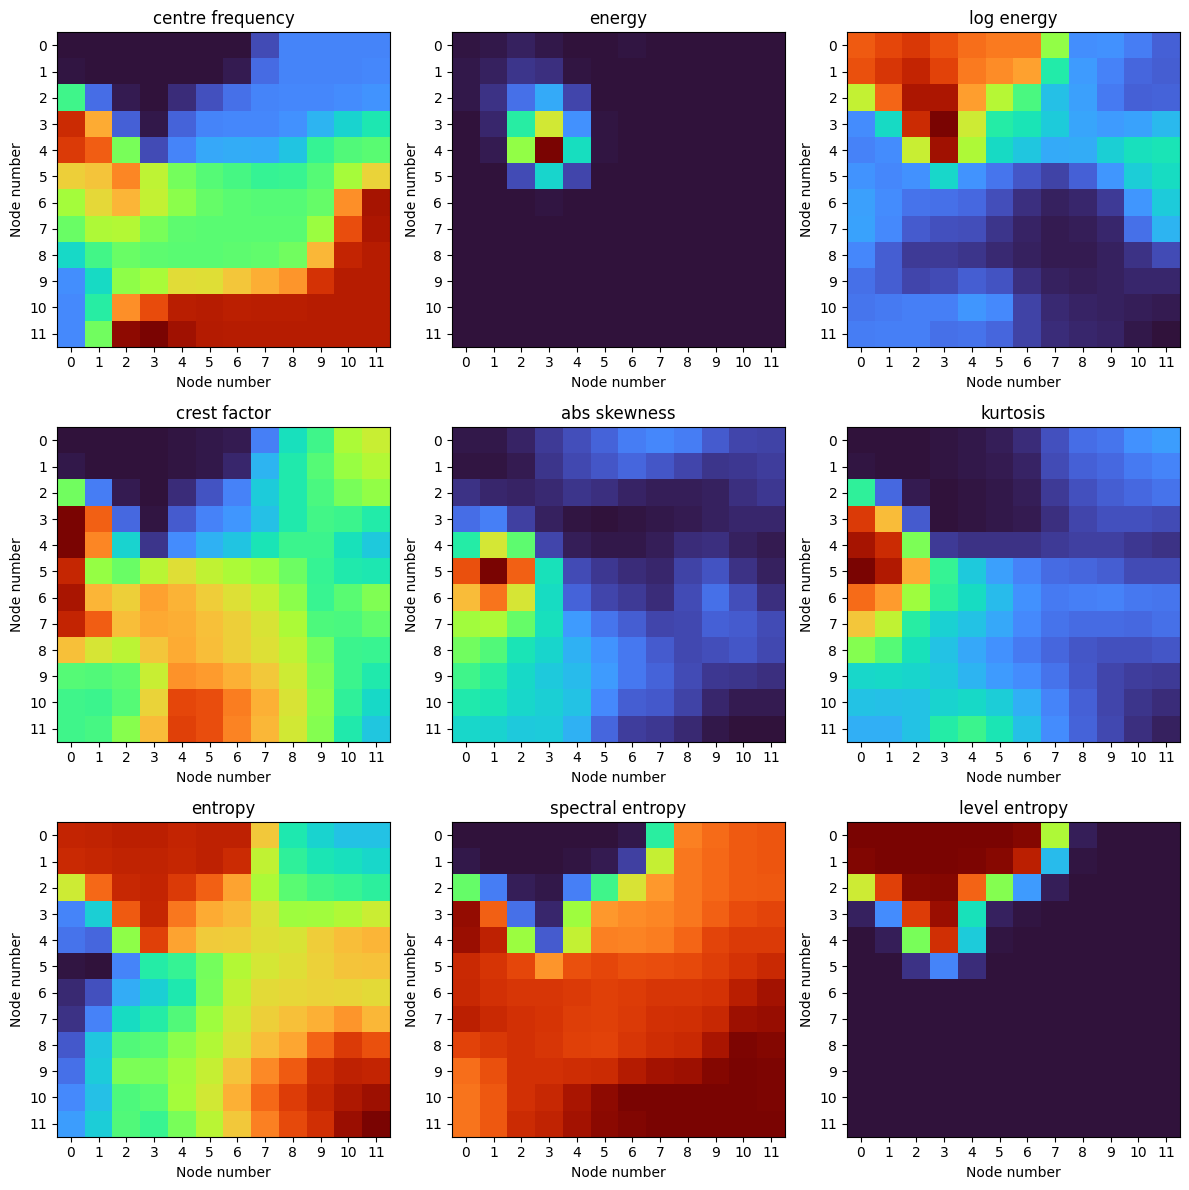

In [46]:
# Plotting heatmaps for each feature
columns = 3
rows = n_metrics / columns
if rows.is_integer() is False:
    rows = int(rows) + 1# round up if there aren't enough rows
rows = max(2, rows)
fig, axes = plt.subplots(int(rows), columns, figsize=(12, 12))

for i, feature in enumerate(classifying_metrics):
    row, col = i // columns, i % columns
    feature_values = centers[:, i].reshape(som_size[::-1])
    # print(centers[:, i])
    ax:plt.Axes = axes[row, col]
    ax.imshow(feature_values, cmap='turbo', aspect='auto')
    ax.set_title(f'{feature}')
    ax.set_xlabel("Node number")
    ax.set_ylabel("Node number")
    ax.set_xticks(range(som_width))
    ax.set_yticks(range(som_height))

plt.tight_layout()
plt.show()